# 6. Quadratic programming with linear constraints

Portfolio exercises 6.1–6.2 ([CO 12.2, 14.6.1]). Section 6.1 solves a
two-variable QP over a polygon, draws the elliptic contours and separates the
unconstrained from the constrained minimiser. Section 6.2 solves an
equality-constrained QP through its KKT system and compares the result with
trust-constr.

Every optimality condition is checked numerically next to where it is used:
gradients, KKT residuals, complementary slackness and the inertia of the KKT
matrix. All random experiments use rng = np.random.default_rng(2026).

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from itertools import combinations
from matplotlib.patches import Polygon
from scipy.optimize import minimize, LinearConstraint
from scipy.linalg import null_space

rng = np.random.default_rng(2026)
plt.rcParams.update({"figure.figsize": (7, 4.2), "axes.grid": True,
                     "grid.alpha": 0.3, "font.size": 9})

## 6.1 A QP you can see [CO 12.2]

### Task

Solve
$$\min_x\;\tfrac12 x^\top Px+q^\top x
\quad\text{s.t.}\quad Gx\le h,\qquad P\succeq0,$$
in 2-D. Plot the elliptic contours, the polygon $Gx\le h$, the unconstrained
minimiser $-P^{-1}q$ and the constrained one.

### Explore

Move $q$ so that the unconstrained minimiser goes in and out of the polygon.
Make $P$ only PSD.

In [12]:
G61 = np.array([[-1.0, 0.0],      # -x1 <= 0
                [0.0, -1.0],     # -x2 <= 0
                [1.0, 1.0],      # x1 + x2 <= 4.5
                [2.0, 1.0],      # 2 x1 + x2 <= 6
                [1.0, 2.0]])     # x1 + 2 x2 <= 6
h61 = np.array([0.0, 0.0, 4.5, 6.0, 6.0])


def P_from_eig(l1, l2, angle_deg):
    """Symmetric PSD matrix with eigenvalues l1, l2 and rotated eigenvectors."""
    t = np.deg2rad(angle_deg)
    R = np.array([[np.cos(t), -np.sin(t)], [np.sin(t), np.cos(t)]])
    return R @ np.diag([l1, l2]) @ R.T


def qp_value(P, q, x):
    return 0.5 * x @ P @ x + q @ x


def qp_slsqp(P, q, G, h):
    """Constrained QP through SLSQP; the polygon contains the origin."""
    res = minimize(lambda z: qp_value(P, q, z), np.zeros(len(q)),
                   jac=lambda z: P @ z + q, method="SLSQP",
                   constraints=[{"type": "ineq",
                                 "fun": lambda z: h - G @ z,
                                 "jac": lambda z: -G}],
                   options={"ftol": 1e-12, "maxiter": 1000})
    assert res.success, res.message
    return res


def qp_active(P, q, G, h):
    """Enumerate active sets and solve the equality-constrained KKT systems."""
    n, m = len(q), len(h)
    best = None
    for k in range(n + 1):
        for S in combinations(range(m), k):
            if k:
                GS = G[list(S)]
                K = np.block([[P, GS.T], [GS, np.zeros((k, k))]])
                try:
                    sol = np.linalg.solve(K, np.r_[-q, h[list(S)]])
                except np.linalg.LinAlgError:
                    continue
                x, lam = sol[:n], sol[n:]
                if np.any(lam < -1e-9):
                    continue
            else:
                x, lam = -np.linalg.solve(P, q), np.zeros(0)
            if np.any(G @ x > h + 1e-8):
                continue
            f = qp_value(P, q, x)
            if best is None or f < best[0] - 1e-12:
                best = (f, x, S, lam)
    assert best is not None, "no feasible active set"
    return best


def polygon_vertices(G, h):
    """Vertices of a bounded polygon, ordered around its centroid."""
    pts = []
    for i, j in combinations(range(len(h)), 2):
        M = np.array([G[i], G[j]])
        if abs(np.linalg.det(M)) < 1e-12:
            continue
        x = np.linalg.solve(M, [h[i], h[j]])
        if (G @ x <= h + 1e-9).all():
            pts.append(np.round(x, 12))
    pts = np.unique(pts, axis=0)
    centre = pts.mean(axis=0)
    return pts[np.argsort(np.arctan2((pts - centre)[:, 1],
                                    (pts - centre)[:, 0]))]


def draw_qp(ax, P, q, G, h, title="", npts=240, nlev=16, show_xu=True):
    """Contours + polygon + both minimisers; returns the SLSQP result."""
    verts = polygon_vertices(G, h)
    res = qp_slsqp(P, q, G, h)
    xu = None
    if show_xu and np.linalg.matrix_rank(P, tol=1e-10) == len(q):
        xu = -np.linalg.solve(P, q)

    pts = verts if xu is None else np.vstack([verts, xu])
    lo = pts.min(axis=0) - 0.7
    hi = pts.max(axis=0) + 0.9
    X, Y = np.meshgrid(np.linspace(lo[0], hi[0], npts),
                       np.linspace(lo[1], hi[1], npts))
    F = 0.5 * (P[0, 0] * X**2 + 2 * P[0, 1] * X * Y + P[1, 1] * Y**2) \
        + q[0] * X + q[1] * Y
    ax.contour(X, Y, F, levels=nlev, cmap="viridis", linewidths=0.8)
    ax.add_patch(Polygon(verts, closed=True, facecolor="tab:blue", alpha=0.12,
                         edgecolor="tab:blue", lw=1.5))

    active = np.flatnonzero(h - G @ res.x < 1e-7)
    grid = np.linspace(lo[0], hi[0], 2)
    for k, i in enumerate(active):
        label = "active constraint" if k == 0 else None
        if abs(G[i, 1]) > 1e-12:
            ax.plot(grid, (h[i] - G[i, 0] * grid) / G[i, 1],
                    color="tab:red", lw=2.0, alpha=0.8, label=label)
        else:
            ax.axvline(h[i] / G[i, 0], color="tab:red", lw=2.0, alpha=0.8,
                       label=label)

    ax.plot(*res.x, "*", color="tab:red", ms=16,
            label=r"constrained $x^\star$", zorder=7)
    if xu is not None:
        ax.plot(*xu, "s", mfc="none", mec="tab:orange", ms=11, mew=1.6,
                label=r"unconstrained $-P^{-1}q$", zorder=8)

    ax.set_xlim(lo[0], hi[0]); ax.set_ylim(lo[1], hi[1])
    ax.set_aspect("equal")
    ax.set_xlabel(r"$x_1$"); ax.set_ylabel(r"$x_2$")
    ax.set_title(title, fontsize=9)
    return res, verts

In [13]:
P61 = P_from_eig(1.0, 3.0, 25.0)
q61 = -P61 @ np.array([4.2, 2.4])          # unconstrained minimiser outside
xu61 = -np.linalg.solve(P61, q61)

f61, x61, S61, lam61 = qp_active(P61, q61, G61, h61)
res61 = qp_slsqp(P61, q61, G61, h61)
lam_full = np.zeros(len(h61)); lam_full[list(S61)] = lam61

print(f"P eigenvalues       : {np.linalg.eigvalsh(P61)}")
print(f"unconstrained x     : {xu61}")
print(f"constrained x*      : {x61}")
print(f"active constraints  : {S61}, multipliers {lam61}")
print(f"objective at x*     : {f61:.6f}")

assert np.linalg.eigvalsh(P61).min() > 0
assert np.allclose(P61 @ xu61 + q61, 0)                       # unconstrained gradient
assert np.allclose(x61, res61.x, atol=1e-7)                   # active set = SLSQP
assert np.allclose(P61 @ x61 + q61 + G61.T @ lam_full, 0)     # stationarity
assert np.all(G61 @ x61 <= h61 + 1e-8)                         # primal feasibility
assert np.all(lam_full >= -1e-9)                               # dual feasibility
assert np.allclose(lam_full * (G61 @ x61 - h61), 0)            # complementary slackness
print("KKT conditions hold at x*")

P eigenvalues       : [1. 3.]
unconstrained x     : [4.2 2.4]
constrained x*      : [2.26251821 1.47496358]
active constraints  : (3,), multipliers [0.96047764]
objective at x*     : -9.554967
KKT conditions hold at x*


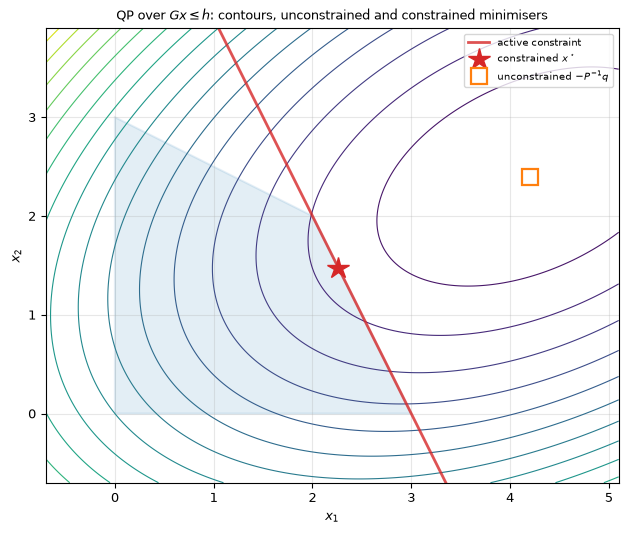

In [14]:
fig, ax = plt.subplots(figsize=(7.0, 5.4))
draw_qp(ax, P61, q61, G61, h61,
        r"QP over $Gx\leq h$: contours, unconstrained and constrained minimisers")
ax.legend(loc="upper right", fontsize=7.5)
plt.tight_layout()
plt.show()

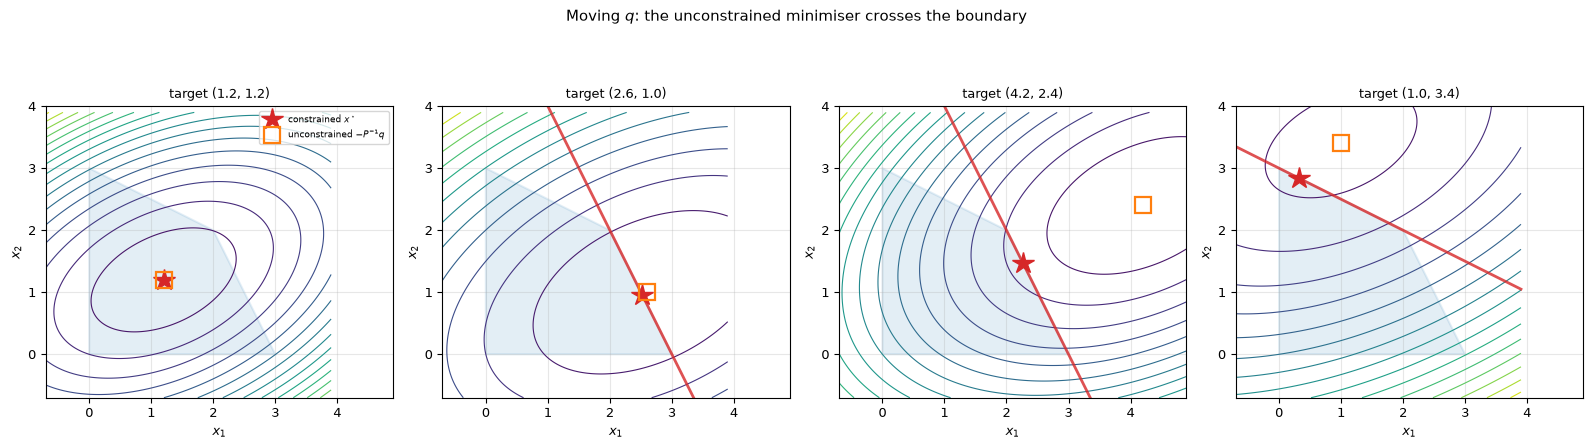

In [15]:
targets = [(1.2, 1.2), (2.6, 1.0), (4.2, 2.4), (1.0, 3.4)]
fig, axes = plt.subplots(1, 4, figsize=(16.0, 4.3))
for ax, target in zip(axes, targets):
    q = -P61 @ np.array(target)
    f, x, S, lam = qp_active(P61, q, G61, h61)
    res = qp_slsqp(P61, q, G61, h61)
    assert np.allclose(x, res.x, atol=1e-7)
    if np.all(G61 @ np.array(target) <= h61 + 1e-9):
        assert S == () and np.allclose(x, target)              # constraint irrelevant
    else:
        assert S != () and np.all(G61 @ x <= h61 + 1e-8)
    draw_qp(ax, P61, q, G61, h61, f"target {target}", npts=180)
    ax.set_xlim(-0.7, 4.9); ax.set_ylim(-0.7, 4.0)
axes[0].legend(loc="upper right", fontsize=6.5)
fig.suptitle(r"Moving $q$: the unconstrained minimiser crosses the boundary", y=1.03)
plt.tight_layout()
plt.show()

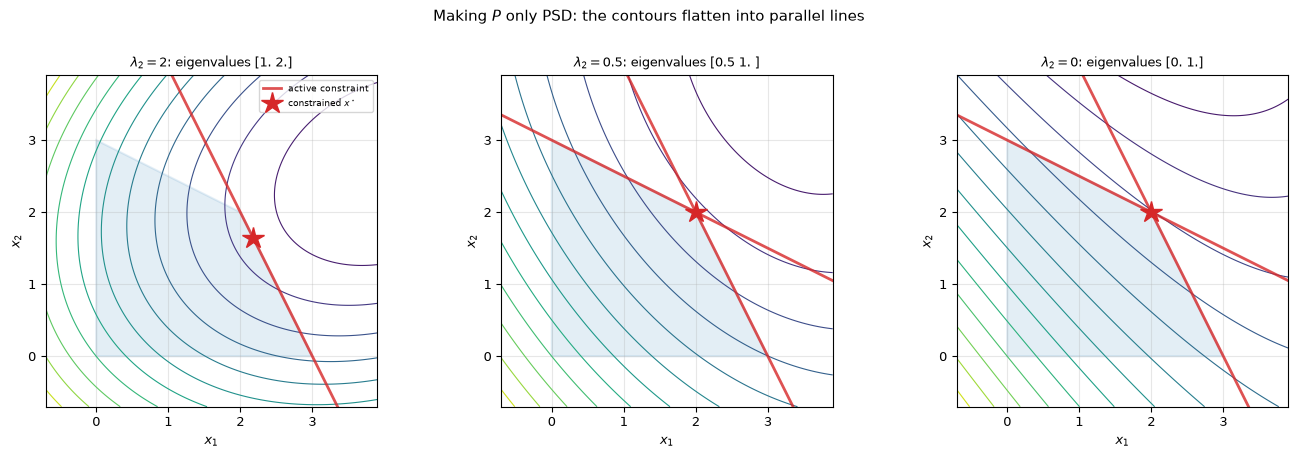

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(13.8, 4.3))
for ax, l2 in zip(axes, [2.0, 0.5, 0.0]):
    P = P_from_eig(1.0, l2, 25.0)
    ev = np.linalg.eigvalsh(P)
    assert ev.min() >= -1e-12                                # P is PSD
    res, verts = draw_qp(ax, P, q61, G61, h61,
                         rf"$\lambda_2={l2:g}$: eigenvalues {np.round(ev, 2)}",
                         npts=180, show_xu=False)
    active = np.flatnonzero(h61 - G61 @ res.x < 1e-7)
    lam, *_ = np.linalg.lstsq(G61[active].T, -(P @ res.x + q61), rcond=None)
    assert np.allclose(G61[active].T @ lam, -(P @ res.x + q61), atol=1e-7)
    assert np.all(lam >= -1e-7)
    assert np.all(G61 @ res.x <= h61 + 1e-7)
axes[0].legend(loc="upper right", fontsize=6.5)
fig.suptitle(r"Making $P$ only PSD: the contours flatten into parallel lines", y=1.03)
plt.tight_layout()
plt.show()

In [17]:
import ipywidgets as widgets
from IPython.display import clear_output, display

out61 = widgets.Output()
s_l1 = widgets.FloatSlider(value=1.0, min=0.2, max=4.0, step=0.1,
                           description=r"$\lambda_1$", continuous_update=False,
                           layout=widgets.Layout(width="320px"))
s_l2 = widgets.FloatSlider(value=3.0, min=0.0, max=4.0, step=0.1,
                           description=r"$\lambda_2$", continuous_update=False,
                           layout=widgets.Layout(width="320px"))
s_th = widgets.FloatSlider(value=25.0, min=0.0, max=90.0, step=1.0,
                           description=r"$\theta$ (deg)", continuous_update=False,
                           layout=widgets.Layout(width="320px"))
s_q1 = widgets.FloatSlider(value=q61[0], min=-6.0, max=2.0, step=0.1,
                           description=r"$q_1$", continuous_update=False,
                           layout=widgets.Layout(width="320px"))
s_q2 = widgets.FloatSlider(value=q61[1], min=-6.0, max=2.0, step=0.1,
                           description=r"$q_2$", continuous_update=False,
                           layout=widgets.Layout(width="320px"))


def redraw61(*_):
    P = P_from_eig(s_l1.value, s_l2.value, s_th.value)
    q = np.array([s_q1.value, s_q2.value])
    with out61:
        clear_output(wait=True)
        fig, ax = plt.subplots(figsize=(6.4, 5.0))
        draw_qp(ax, P, q, G61, h61,
                rf"$\lambda=({s_l1.value:.1f},{s_l2.value:.1f})$, "
                rf"$\theta={s_th.value:.0f}^\circ$")
        ax.legend(loc="upper right", fontsize=7)
        plt.tight_layout()
        plt.show()


for s in (s_l1, s_l2, s_th, s_q1, s_q2):
    s.observe(redraw61, names="value")
display(widgets.VBox([s_l1, s_l2, s_th, s_q1, s_q2, out61]))
redraw61()

### Explain

The constraint is irrelevant exactly when the unconstrained minimiser $-P^{-1}q$
is in the feasible set. Because it doesn't cross the cone.

With $n$ variables, at most $n$ linearly independent constraints can be active
at a regular point.

## 6.2 Equality-constrained QP and the KKT system [CO 12.2, 14.5.4, 14.3.2]

### Task

For random $P\succ0$ ($n=5$) and $A\in\mathbb R^{2\times5}$, solve
$$\min_x\;\tfrac12 x^\top Px+q^\top x
\quad\text{s.t.}\quad Ax=b$$
by solving the KKT system
$$\begin{pmatrix}P&A^\top\\A&0\end{pmatrix}
\begin{pmatrix}x^\star\\\nu^\star\end{pmatrix}
=\begin{pmatrix}-q\\b\end{pmatrix},$$
and compare with scipy.optimize.minimize(method="trust-constr").

### Explore

Check whether the KKT matrix is symmetric and positive definite. With $P=2I$ and
$q=0$, recover the minimum-norm solution $A^\top(AA^\top)^{-1}b$ of [CO 14.3.2].

In [18]:
n62, p62 = 5, 2
B62 = rng.normal(size=(n62, n62))
P62 = B62.T @ B62 + 0.5 * np.eye(n62)       # P is positive definite
A62 = rng.normal(size=(p62, n62))
b62 = rng.normal(size=p62)
q62 = rng.normal(size=n62)
assert np.linalg.matrix_rank(A62) == p62     # A has full row rank


def kkt_solve(P, q, A, b):
    """Solve the equality-constrained QP through its KKT system."""
    n, p = len(q), A.shape[0]
    K = np.block([[P, A.T], [A, np.zeros((p, p))]])
    sol = np.linalg.solve(K, np.r_[-q, b])
    return sol[:n], sol[n:], K


def eq_value(x):
    return 0.5 * x @ P62 @ x + q62 @ x


x62, nu62, K62 = kkt_solve(P62, q62, A62, b62)
res62 = minimize(eq_value, np.zeros(n62), jac=lambda z: P62 @ z + q62,
                 hess=lambda z: P62, method="trust-constr",
                 constraints=LinearConstraint(A62, b62, b62),
                 options={"gtol": 1e-12, "xtol": 1e-12, "maxiter": 2000})

print(f"KKT x*              : {x62}")
print(f"trust-constr x      : {res62.x}")
print(f"max |x_KKT - x_TC|  : {np.max(np.abs(x62 - res62.x)):.3e}")
print(f"primal residual     : {np.max(np.abs(A62 @ x62 - b62)):.3e}")
print(f"stationarity residual: {np.max(np.abs(P62 @ x62 + A62.T @ nu62 + q62)):.3e}")

assert np.allclose(A62 @ x62, b62)                                  # primal feasibility
assert np.allclose(P62 @ x62 + A62.T @ nu62 + q62, 0)               # stationarity
assert np.allclose(x62, res62.x, atol=1e-7)                         # agree with trust-constr
assert abs(eq_value(x62) - res62.fun) < 1e-9

ev62 = np.linalg.eigvalsh(K62)
print(f"KKT eigenvalues     : {np.round(ev62, 4)}")
assert np.allclose(K62, K62.T)                                      # symmetric
assert np.sum(ev62 < 0) == p62 and np.sum(ev62 > 0) == n62          # inertia (n, p)
print("KKT matrix is symmetric indefinite and invertible")

KKT x*              : [ 0.30877872 -0.17161576  0.07893591  0.10548936  0.12625103]
trust-constr x      : [ 0.30877872 -0.17161576  0.07893591  0.10548936  0.12625103]
max |x_KKT - x_TC|  : 7.332e-11
primal residual     : 1.110e-16
stationarity residual: 2.776e-16
KKT eigenvalues     : [-2.3846 -0.7537  0.7429  1.2901  2.3043  4.287   8.7646]
KKT matrix is symmetric indefinite and invertible


In [19]:
P_id = 2.0 * np.eye(n62)
q_id = np.zeros(n62)
x_id, nu_id, K_id = kkt_solve(P_id, q_id, A62, b62)

AT = A62.T
G_id = A62 @ AT
x_min = AT @ np.linalg.solve(G_id, b62)           # A^T (A A^T)^{-1} b
nu_min = -2.0 * np.linalg.solve(G_id, b62)

res_id = minimize(lambda z: z @ z, np.zeros(n62), jac=lambda z: 2 * z,
                  hess=lambda z: 2 * np.eye(n62), method="trust-constr",
                  constraints=LinearConstraint(A62, b62, b62),
                  options={"gtol": 1e-12, "xtol": 1e-12, "maxiter": 2000})
N62 = null_space(A62)

print(f"max |x_KKT - x_min|  : {np.max(np.abs(x_id - x_min)):.3e}")
print(f"max |nu_KKT - nu_min|: {np.max(np.abs(nu_id - nu_min)):.3e}")
print(f"max |x_min . null(A)|: {np.max(np.abs(x_min @ N62)):.3e}")
print(f"max |x_min - trust  |: {np.max(np.abs(x_min - res_id.x)):.3e}")

assert np.allclose(x_id, x_min)                    # KKT recovers the min-norm solution
assert np.allclose(nu_id, nu_min)
assert np.allclose(x_min @ N62, 0, atol=1e-12)     # x_min is orthogonal to null(A)
assert np.allclose(res_id.x, x_min, atol=1e-7)     # trust-constr agrees
assert np.allclose(np.linalg.lstsq(A62, b62, rcond=None)[0], x_min)

max |x_KKT - x_min|  : 2.776e-17
max |nu_KKT - nu_min|: 2.776e-17
max |x_min . null(A)|: 1.517e-17
max |x_min - trust  |: 8.327e-17


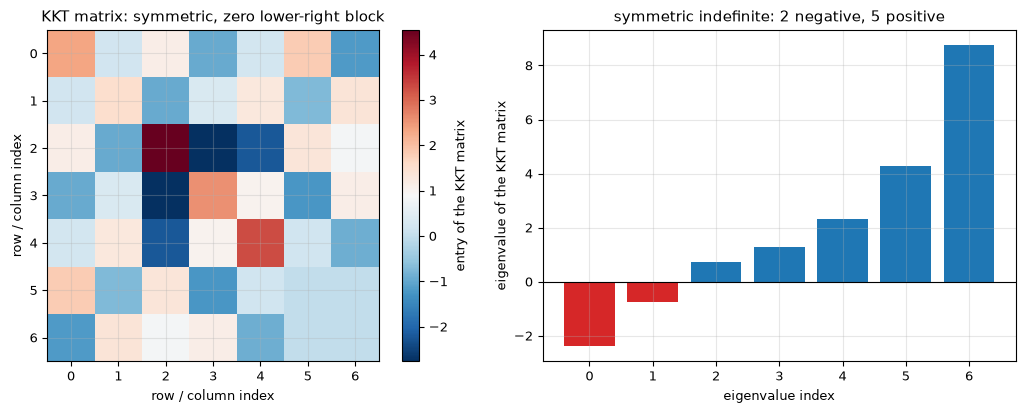

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(10.8, 4.2))
im = axes[0].imshow(K62, cmap="RdBu_r")
cbar = fig.colorbar(im, ax=axes[0])
cbar.set_label("entry of the KKT matrix")
axes[0].set_xlabel("row / column index")
axes[0].set_ylabel("row / column index")
axes[0].set_title("KKT matrix: symmetric, zero lower-right block")

ev = np.linalg.eigvalsh(K62)
axes[1].bar(np.arange(len(ev)), ev,
            color=["tab:red" if e < 0 else "tab:blue" for e in ev])
axes[1].axhline(0, color="k", lw=0.8)
axes[1].set_xlabel("eigenvalue index")
axes[1].set_ylabel("eigenvalue of the KKT matrix")
axes[1].set_title(rf"symmetric indefinite: {np.sum(ev < 0)} negative, "
                  rf"{np.sum(ev > 0)} positive")
plt.tight_layout()
plt.show()

### Explain

The KKT matrix is symmetric because $P$ is symmetric and the
two $A$ blocks are transposes. It is not positive definite, it is just symmetric.

For $P=2I$ and $q=0$, stationarity gives $x=-A^\top\nu/2$; imposing $Ax=b$ gives
$\nu=-2(AA^\top)^{-1}b$ and $x=A^\top(AA^\top)^{-1}b$.